# Customer Segmentation – EDA & Clustering

End-to-end analysis: exploratory data analysis, optimal-k selection, KMeans clustering, and cluster interpretation.


In [135]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from collections import namedtuple
from kneed import KneeLocator
import hdbscan

sns.set_theme(style='whitegrid', palette='tab10')
%matplotlib inline
print('Libraries loaded.')

Libraries loaded.


## 1· Load Preprocessed Data

In [136]:
PROCESSED_PATH = '../data/processed/customer_segmentation_processed.csv'
df_processed = pd.read_csv(PROCESSED_PATH)
print(f'Shape: {df_processed.shape}')
df_processed.head()

Shape: (2236, 24)


,ID,numeric__Education,numeric__Income,numeric__Recency,numeric__Kidhome,numeric__Teenhome,numeric__children,numeric__familySize,numeric__is_parent,numeric__Marital_Status,...,log__MntFishProducts,log__MntSweetProducts,log__MntGoldProds,log__NumDealsPurchases,log__NumWebPurchases,log__NumCatalogPurchases,log__NumStorePurchases,log__NumWebVisitsMonth,log__amountSpent,log__numPurchases
0,5524,-0.792105,0.288126,0.306856,-0.824939,-0.930615,-1.264308,-1.758810,-1.584362,-1.347635,...,1.579760,1.410558,1.062164,0.652625,1.280181,1.804684,-0.394879,0.706206,1.202519,1.128552
1,2174,-0.792105,-0.260839,-0.383971,1.032627,0.905974,1.395139,0.445618,0.631169,-1.347635,...,-0.866121,-0.971131,-0.912916,0.042160,-1.396608,-0.405821,-1.445012,0.087735,-1.558363,-1.210009
2,4141,-0.792105,0.915335,-0.798467,-0.824939,-0.930615,-1.264308,-0.656596,-1.584362,0.742041,...,1.317483,0.533561,0.497123,-0.818241,1.280181,0.119936,1.225998,-0.304227,0.703320,0.830830
3,6182,-0.792105,-1.177706,-0.798467,1.032627,-0.930615,0.065416,0.445618,0.631169,0.742041,...,-0.082362,-0.536177,-1.032654,0.042160,-0.675007,-1.304608,-0.394879,0.419135,-1.111381,-0.762120
4,5324,1.590069,0.295341,1.550344,1.032627,-0.930615,0.065416,0.445618,0.631169,0.742041,...,0.793672,0.684891,-0.270788,1.513026,0.558579,0.492966,0.296827,0.087735,0.289489,0.660970


In [137]:
# extract IDs into a separate container
customer_ids = df_processed["ID"].copy()
# Create a deep copy for EDA and modifications
df_modeling = df_processed.drop(columns=["ID"]).copy()

## 2. Apply PCA

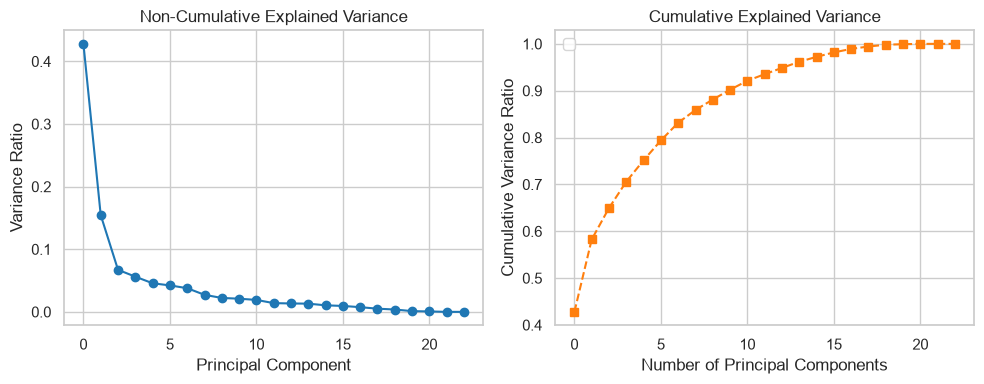

In [138]:
# Fit PCA without a component limit to see all available dimensions
pca_full = PCA().fit(df_modeling)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Non-cumulative plot
ax1.plot(pca_full.explained_variance_ratio_, "o-", color="tab:blue")
ax1.set_title("Non-Cumulative Explained Variance")
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Variance Ratio")
ax1.grid(True)

# Cumulative plot
ax2.plot(np.cumsum(pca_full.explained_variance_ratio_), "s--", color="tab:orange")
ax2.set_title("Cumulative Explained Variance")
ax2.set_xlabel("Number of Principal Components")
ax2.set_ylabel("Cumulative Variance Ratio")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [139]:
# Initialize and fit PCA

# Automatically retain 85% of total variance
pca = PCA(n_components = 0.85)

# Transform the data into the new PCA space
pca_features = pca.fit_transform(df_modeling)

# Get the exact number of components selected
n_comps = pca.n_components_
# Simply rename the columns on the returned DataFrame
pca_features = pd.DataFrame(
    pca_features,
    columns=[f"PC{i+1}" for i in range(n_comps)],
    index=df_modeling.index,
)
pca_df = pca_features

# Inspect the Results
print("--- Transformed PCA Coordinates ---")
print(pca_df.head(5))

print("\n--- Percentage of Variance Explained by Each Component ---")
# Tells you how much information each Principal Component holds
print(pca.explained_variance_ratio_)

--- Transformed PCA Coordinates ---
        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0  4.400747 -0.810891 -1.266028 -1.824368  0.644175 -0.154636 -1.049783   
1 -3.957784  0.069050  0.876889 -0.728605  1.591644 -1.436850  0.895079   
2  3.417983 -1.122668 -0.376843  0.666849 -0.652154 -0.826016 -0.957208   
3 -3.020398 -1.022496 -1.488728  0.793704 -0.965426 -0.317109  0.179307   
4  0.914439  1.117333 -1.114209  0.671884 -0.700569  2.678163  0.803960   

        PC8  
0  1.504563  
1  0.493838  
2  0.217798  
3 -0.101108  
4  1.090986  

--- Percentage of Variance Explained by Each Component ---
[0.42796882 0.15459799 0.06716116 0.05622108 0.04568795 0.04226781
 0.03781171 0.02722086]


## 3· K-Means Clustering 
#### Optimal k Selection

In [140]:
# Evaluation Loop to gather metrics
k_range = range(2, 8)  # Testing 2 through 7 clusters
wss = []
silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores= []

# Loop through each K value and compute the metrics
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(pca_df)
    
    wss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(pca_df, kmeans.labels_)),
    davies_bouldin_scores.append(davies_bouldin_score(pca_df, kmeans.labels_)),
    calinski_harabasz_scores.append(calinski_harabasz_score(pca_df, kmeans.labels_)),

# Determine the best K for each metric
# Automatically find the elbow point
kn = KneeLocator(k_range, wss, curve='convex', direction='decreasing')
rec_k_wss = kn.knee
rec_k_silhouette = k_range[np.argmax(silhouette_scores)]
rec_k_db = k_range[np.argmin(davies_bouldin_scores)]
rec_k_ch = k_range[np.argmax(calinski_harabasz_scores)]

# Print K for each metric
print("\n" + "="*45)
print(f"{'Method / Metric':<25} | {'Recommended K':<15}")
print("="*45)
print(f"{'WSS / Elbow Method':<25} | {rec_k_wss:<15}")
print(f"{'Silhouette Score':<25} | {rec_k_silhouette:<15}")
print(f"{'Davies-Bouldin Index':<25} | {rec_k_db:<15}")
print(f"{'Calinski-Harabasz Index':<25} | {rec_k_ch:<15}")
print("="*45 + "\n")


# store the results
KResult = namedtuple('KResult', ['k_range', 'wss', 
                                 'silhouette_scores', 'davies_bouldin_scores', 
                                 'calinski_harabasz_scores', 
                                 'recommended_k'
                                 ])
k_result = KResult(k_range=list(k_range), wss=wss, 
                   silhouette_scores=silhouette_scores, 
                   davies_bouldin_scores=davies_bouldin_scores,
                   calinski_harabasz_scores=calinski_harabasz_scores,
                   recommended_k=rec_k_wss
                   )



Method / Metric           | Recommended K  
WSS / Elbow Method        | 3              
Silhouette Score          | 2              
Davies-Bouldin Index      | 2              
Calinski-Harabasz Index   | 2              



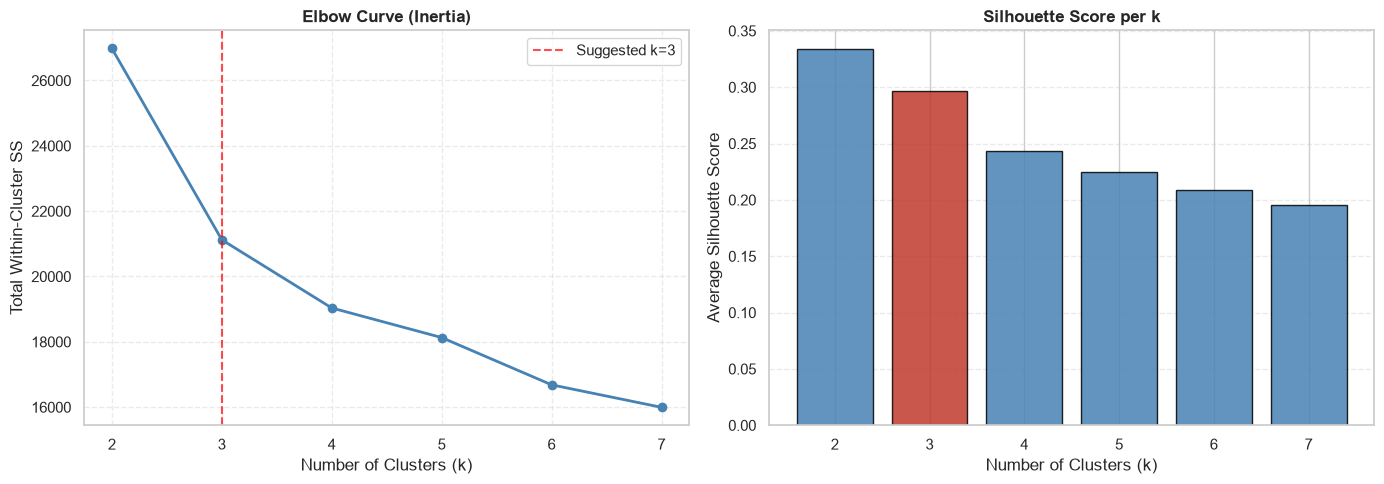

In [141]:
# Plot for optimal K selection 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow
ax1.plot(k_result.k_range, k_result.wss, marker='o', color='steelblue', linewidth=2)
ax1.axvline(k_result.recommended_k, color='red', linestyle='--', alpha=0.7,
            label=f'Suggested k={k_result.recommended_k}')
ax1.set_title('Elbow Curve (Inertia)', fontweight='bold')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Total Within-Cluster SS')
ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.4)


# Silhouette bar
colours = ['#c0392b' if k == k_result.recommended_k else 'steelblue' for k in k_result.k_range]
ax2.bar(k_result.k_range, k_result.silhouette_scores, color=colours, edgecolor='black', alpha=0.85)
ax2.set_title('Silhouette Score per k', fontweight='bold')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Average Silhouette Score')
ax2.set_xticks(k_result.k_range)
ax2.grid(axis='y', linestyle='--', alpha=0.4)


fig.tight_layout()
#plt.savefig('../reports/figures/05_optimal_k.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Applying HDBSCAN Clustering 

In [142]:

# Define the smallest acceptable marketing persona size
clusterer = hdbscan.HDBSCAN(min_cluster_size=50, gen_min_span_tree=True)

# df convert to numpy array and fit HDBSCAN
X_hdb = pca_df.to_numpy(dtype=float, copy=True)
cluster_labels = clusterer.fit_predict(X_hdb)

# Total automated clusters found (excluding noise labeled as -1)
num_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
print(f"HDBSCAN automatically discovered {num_clusters} clusters.")



HDBSCAN automatically discovered 2 clusters.


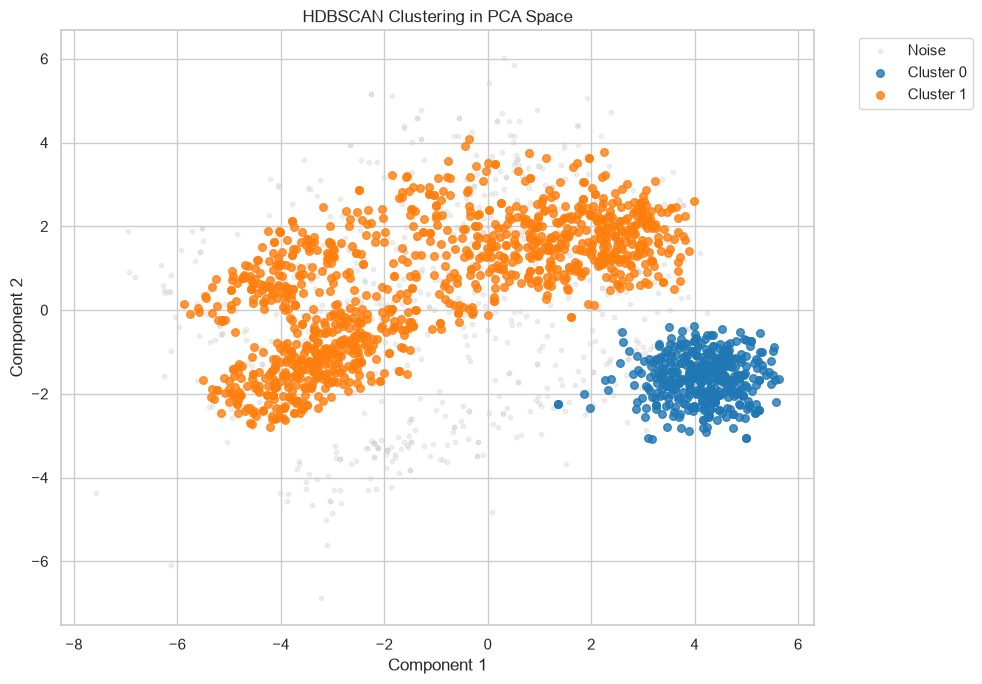

In [143]:
# Visualize the HDBSCAN clustering results in PCA space

labels = clusterer.labels_
unique_labels = set(labels)

plt.figure(figsize=(10, 7))

# Create a custom palette where noise (-1) is muted light gray
palette = sns.color_palette('tab10', len(unique_labels) - (1 if -1 in unique_labels else 0))
colors = {label: palette[i] for i, label in enumerate(sorted(list(unique_labels - {-1})))}
colors[-1] = (0.8, 0.8, 0.8, 0.3)  # Translucent Light Gray for noise

# Plot each cluster individually to control layering (put noise in the background)
for k in sorted(list(unique_labels)):
    mask = (labels == k)
    if k == -1:
        plt.scatter(pca_df.iloc[mask, 0], pca_df.iloc[mask, 1], 
                    c=[colors[k]], label='Noise', s=10, alpha=0.3)
    else:
        plt.scatter(pca_df.iloc[mask, 0], pca_df.iloc[mask, 1], 
                    c=[colors[k]], label=f'Cluster {k}', s=30, alpha=0.8)

plt.title('HDBSCAN Clustering in PCA Space')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


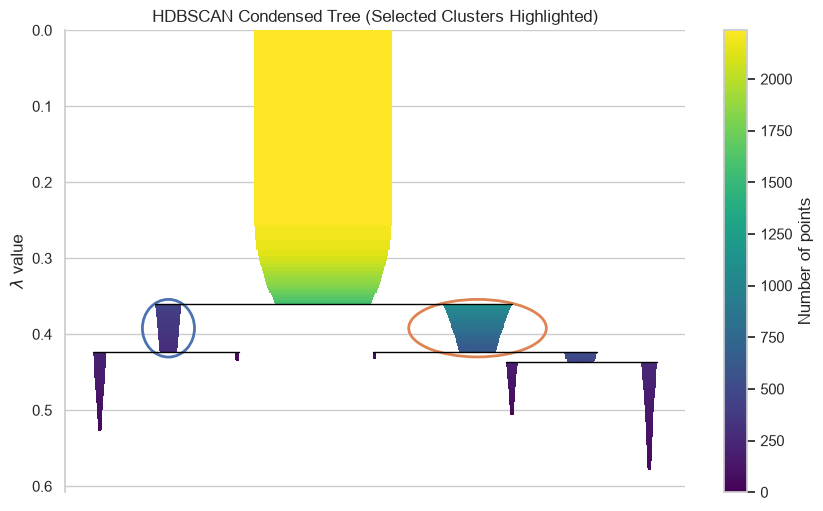

In [144]:
# Visualize the HDBSCAN condensed tree to understand cluster hierarchy and stability
plt.figure(figsize=(10, 6))
clusterer.condensed_tree_.plot(select_clusters=True,
                               selection_palette=sns.color_palette('deep', 8))
plt.title('HDBSCAN Condensed Tree (Selected Clusters Highlighted)')
plt.show()


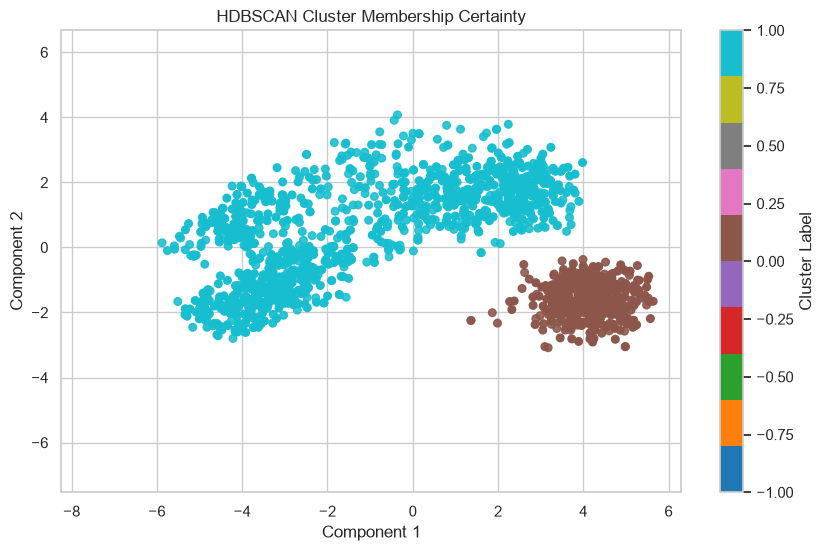

In [145]:
# Plot all points, shading them by how strongly they belong to their cluster
plt.figure(figsize=(10, 6))
scatter = plt.scatter(pca_df.iloc[:, 0], pca_df.iloc[:, 1], 
                      c=labels, 
                      cmap='tab10', 
                      alpha=clusterer.probabilities_, # Use probability for transparency!
                      s=30)

plt.title('HDBSCAN Cluster Membership Certainty')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.colorbar(scatter, label='Cluster Label')
plt.show()


## 5 · Fit Final KMeans Model

In [59]:
# Final Master Pipeline
final_cluster_pipeline = Pipeline([
    ('pca', PCA(n_components=n_comps, random_state=42)),
    ('cluster', KMeans(n_clusters= k_result.recommended_k , random_state=42, n_init='auto')) #
])

# Fit the entire process at once
final_cluster_pipeline.fit(df_modeling)
df_modeling['cluster_label'] = final_cluster_pipeline.named_steps['cluster'].labels_ + 1

In [60]:
# check the first few rows of the modified DataFrame
df_modeling.head()

,numeric__Education,numeric__Income,numeric__Recency,numeric__Kidhome,numeric__Teenhome,numeric__children,numeric__familySize,numeric__is_parent,numeric__Marital_Status,numeric__Age,...,log__MntSweetProducts,log__MntGoldProds,log__NumDealsPurchases,log__NumWebPurchases,log__NumCatalogPurchases,log__NumStorePurchases,log__NumWebVisitsMonth,log__amountSpent,log__numPurchases,cluster_label
0,-0.792105,0.288126,0.306856,-0.824939,-0.930615,-1.264308,-1.758810,-1.584362,-1.347635,1.016868,...,1.410558,1.062164,0.652625,1.280181,1.804684,-0.394879,0.706206,1.202519,1.128552,2
1,-0.792105,-0.260839,-0.383971,1.032627,0.905974,1.395139,0.445618,0.631169,-1.347635,1.273264,...,-0.971131,-0.912916,0.042160,-1.396608,-0.405821,-1.445012,0.087735,-1.558363,-1.210009,3
2,-0.792105,0.915335,-0.798467,-0.824939,-0.930615,-1.264308,-0.656596,-1.584362,0.742041,0.333146,...,0.533561,0.497123,-0.818241,1.280181,0.119936,1.225998,-0.304227,0.703320,0.830830,2
3,-0.792105,-1.177706,-0.798467,1.032627,-0.930615,0.065416,0.445618,0.631169,0.742041,-1.290693,...,-0.536177,-1.032654,0.042160,-0.675007,-1.304608,-0.394879,0.419135,-1.111381,-0.762120,3
4,1.590069,0.295341,1.550344,1.032627,-0.930615,0.065416,0.445618,0.631169,0.742041,-1.034298,...,0.684891,-0.270788,1.513026,0.558579,0.492966,0.296827,0.087735,0.289489,0.660970,1


In [61]:
# check the unique cluster labels assigned to the DataFrame
df_modeling.cluster_label.unique()

array([2, 3, 1], dtype=int32)

## 6 · Cluster Interpretation

In [62]:
# combine cluster lebals with interim data for further analysis and visualization

# used columns
NUM_COLS = ['Education', 'Income','Recency', 'Kidhome', 'Teenhome',
             'children', 'familySize', 'is_parent', 'Marital_Status', 'Age']                                             

LOG_COLS = ['MntWines','MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
            'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 
            'amountSpent' , 'numPurchases'    
                ]

# Load the interim dataset
INTERIM_PATH = '../data/interim/customer_segmentation_interim.csv'
df_prediction = pd.read_csv(INTERIM_PATH, usecols=NUM_COLS+LOG_COLS+['ID'])

# Map the cluster labels from the modeling DataFrame to the prediction DataFrame based on customer IDs
cluster_by_id = pd.Series(
    df_modeling["cluster_label"].to_numpy(),
    index=customer_ids.to_numpy(),
)

df_prediction["cluster_label"] = (
    df_prediction["ID"].map(cluster_by_id)
)

df_prediction.head()

,ID,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,amountSpent,numPurchases,Age,children,familySize,is_parent,cluster_label
0,5524,2.0,1.0,58138.0,0.0,0.0,58.0,635.0,88.0,546.0,...,10.0,4.0,7.0,1617.0,25.0,64.0,0.0,1.0,0,2
1,2174,2.0,1.0,46344.0,1.0,1.0,38.0,11.0,1.0,6.0,...,1.0,2.0,5.0,27.0,6.0,67.0,2.0,3.0,1,3
2,4141,2.0,2.0,71613.0,0.0,0.0,26.0,426.0,49.0,127.0,...,2.0,10.0,4.0,776.0,21.0,56.0,0.0,2.0,0,2
3,6182,2.0,2.0,26646.0,1.0,0.0,26.0,11.0,4.0,20.0,...,0.0,4.0,6.0,53.0,8.0,37.0,1.0,3.0,1,3
4,5324,4.0,2.0,58293.0,1.0,0.0,94.0,173.0,43.0,118.0,...,3.0,6.0,5.0,422.0,19.0,40.0,1.0,3.0,1,1


In [63]:
profile = df_prediction.groupby('cluster_label')[NUM_COLS + LOG_COLS].mean().round(0)
profile

,Education,Income,Recency,Kidhome,Teenhome,children,familySize,is_parent,Marital_Status,Age,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,amountSpent,numPurchases
cluster_label,,,,,,,,,,,,,,,,,,,,,
1,3.0,58598.0,50.0,0.0,1.0,1.0,3.0,1.0,2.0,55.0,...,37.0,28.0,60.0,4.0,6.0,3.0,7.0,6.0,733.0,20.0
2,3.0,73240.0,50.0,0.0,0.0,0.0,2.0,0.0,2.0,53.0,...,91.0,63.0,72.0,1.0,5.0,6.0,8.0,3.0,1298.0,20.0
3,3.0,33067.0,48.0,1.0,0.0,1.0,3.0,1.0,2.0,49.0,...,5.0,4.0,13.0,2.0,2.0,0.0,3.0,7.0,72.0,7.0


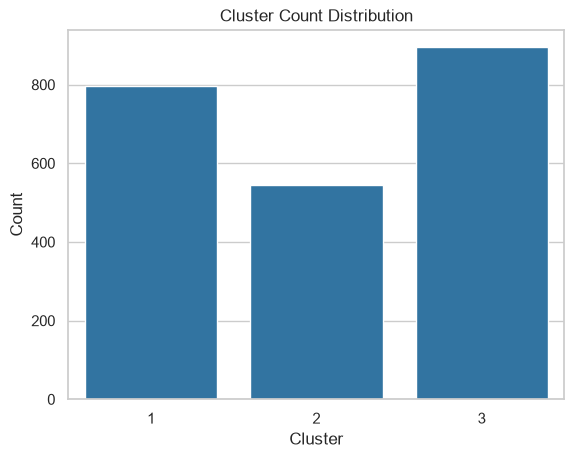

In [64]:
# Cluster Count Distribution
ax = sns.countplot(data=df_prediction, x='cluster_label')

# set title and labels
ax.set_title('Cluster Count Distribution')
ax.set_xlabel('Cluster')
ax.set_ylabel('Count')
plt.show()

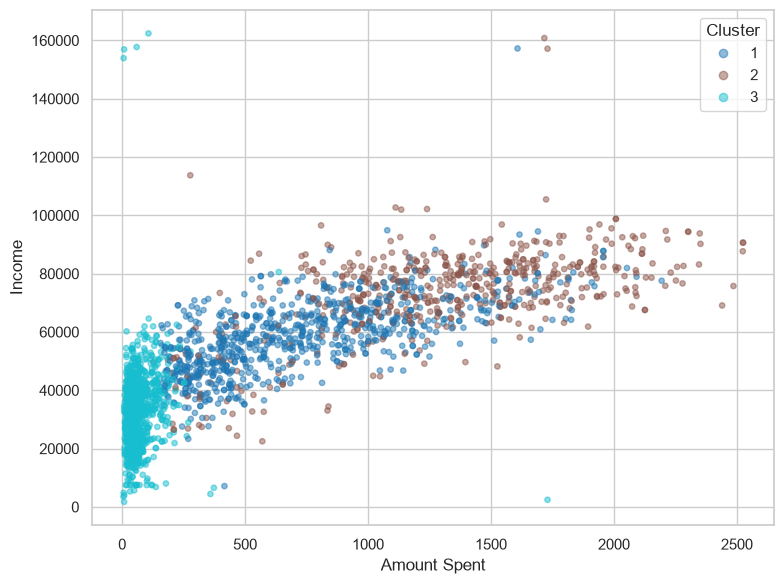

In [65]:
# Plot the clusters by Income vs Amount Spent
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(df_prediction['amountSpent'], df_prediction['Income'],
                     c=df_prediction.cluster_label, cmap='tab10', s=15, alpha=0.5)
handles, labels = scatter.legend_elements()
ax.legend(handles, labels, title="Cluster", loc="upper right")
ax.set_xlabel('Amount Spent'); ax.set_ylabel('Income')
fig.tight_layout()
#plt.savefig('../reports/figures/08_cluster_income_vs_spend.png', dpi=150, bbox_inches='tight')
plt.show()

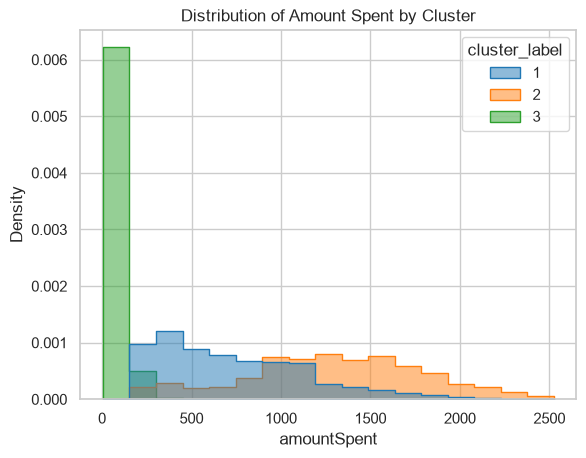

In [66]:
# distribution of amountSpent by clusters
sns.histplot(data=df_prediction, x="amountSpent", hue="cluster_label", element="step", 
             stat="density", common_norm=False, alpha=0.5, palette="tab10")

plt.title("Distribution of Amount Spent by Cluster")
plt.show()

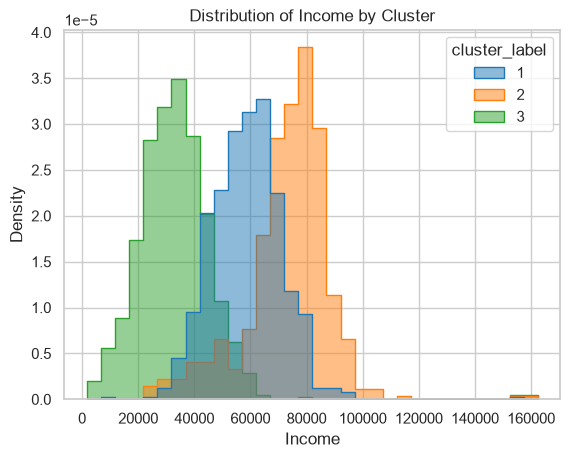

In [67]:
# Overlapping histograms separated by a categorical column
sns.histplot(data=df_prediction, x="Income", hue="cluster_label", element="step", 
             stat="density", common_norm=False, alpha=0.5, palette="tab10")

plt.title("Distribution of Income by Cluster")
plt.show()

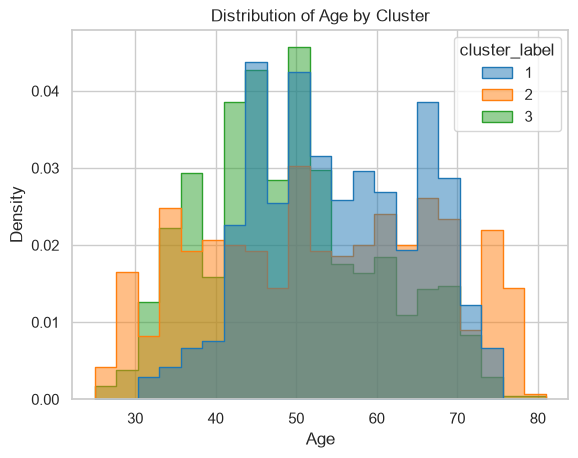

In [68]:
# Overlapping histograms separated by a categorical column
sns.histplot(data=df_prediction, x="Age", hue="cluster_label", element="step", 
             stat="density", common_norm=False, alpha=0.5, palette="tab10")

plt.title("Distribution of Age by Cluster")
plt.show()

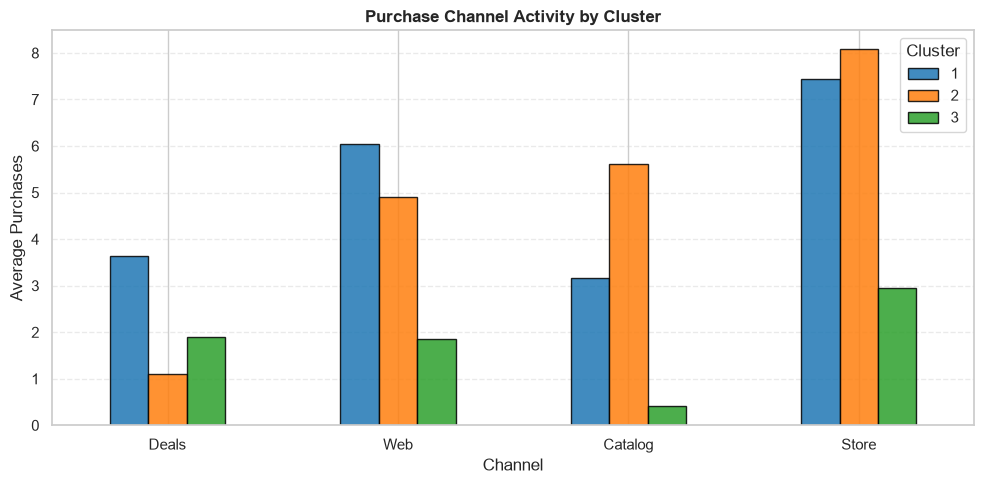

In [69]:
# Purchase channel breakdown
channel_cols = [c for c in ['NumDealsPurchases','NumWebPurchases',
                             'NumCatalogPurchases','NumStorePurchases'] if c in df_prediction.columns]
ch_means = df_prediction.groupby('cluster_label')[channel_cols].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ch_means.T.plot(kind='bar', ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Purchase Channel Activity by Cluster', fontweight='bold')
ax.set_xlabel('Channel'); ax.set_ylabel('Average Purchases')
ax.set_xticklabels(['Deals','Web','Catalog','Store'], rotation=0)
ax.legend(title='Cluster'); ax.grid(axis='y', linestyle='--', alpha=0.4)
fig.tight_layout()
#plt.savefig('../reports/figures/10_purchase_channels.png', dpi=150, bbox_inches='tight')
plt.show()

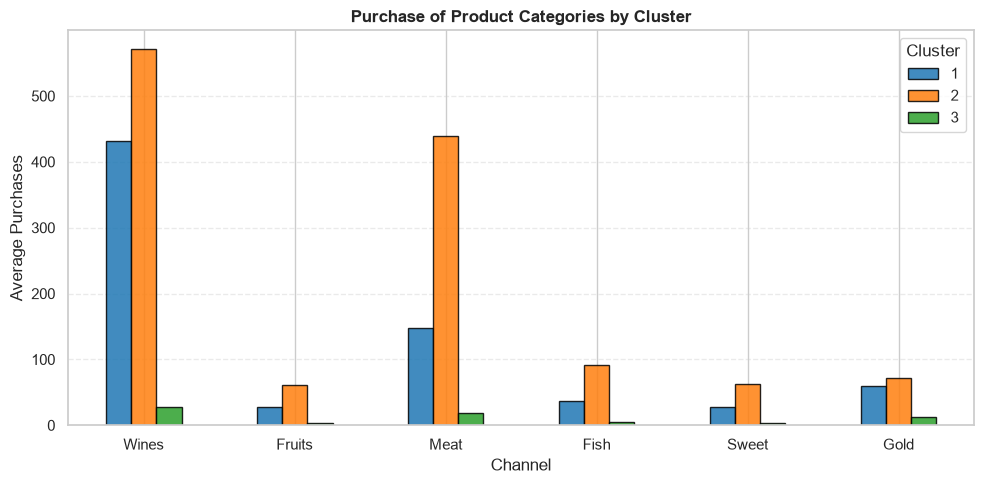

In [86]:
# Purchase channel breakdown
products_cols = [c for c in ['MntWines','MntFruits', 'MntMeatProducts', 
                            'MntFishProducts', 'MntSweetProducts', 'MntGoldProds'] if c in df_prediction.columns]
ch_means = df_prediction.groupby('cluster_label')[products_cols].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ch_means.T.plot(kind='bar', ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Purchase of Product Categories by Cluster', fontweight='bold')
ax.set_xlabel('Channel'); ax.set_ylabel('Average Purchases')
ax.set_xticklabels(['Wines','Fruits','Meat','Fish','Sweet','Gold'], rotation=0)
ax.legend(title='Cluster'); ax.grid(axis='y', linestyle='--', alpha=0.4)
fig.tight_layout()
#plt.savefig('../reports/figures/10_purchase_channels.png', dpi=150, bbox_inches='tight')
plt.show()

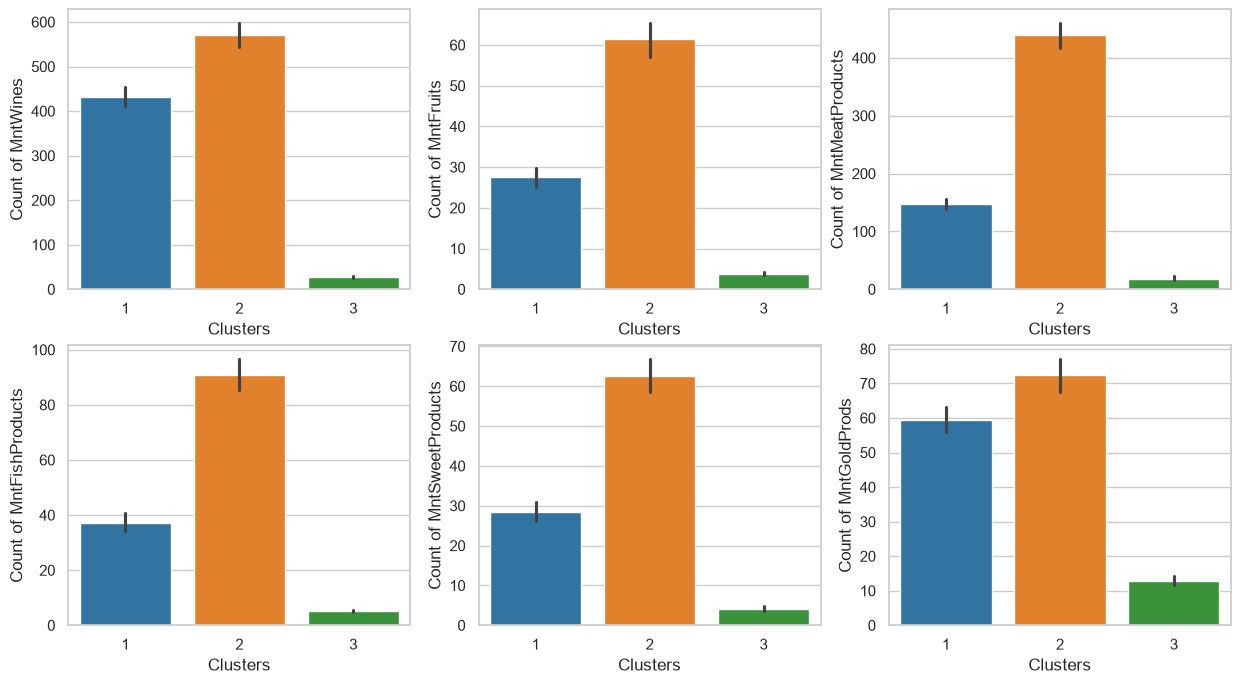

In [107]:
# 2. Initialize the figure and flatten the axes array for easy looping
fig, axes = plt.subplots(2, 3, figsize=(5 * 3, 4 * 2))
axes = axes.flatten()

# bar char for categorical features
for i, col in enumerate(products_cols):
    sns.barplot(data=df_prediction, x='cluster_label', y=col, palette="tab10", ax=axes[i])
    axes[i].set_xlabel('Clusters')
    axes[i].set_ylabel(f'Count of {col}')

plt.show()
print()

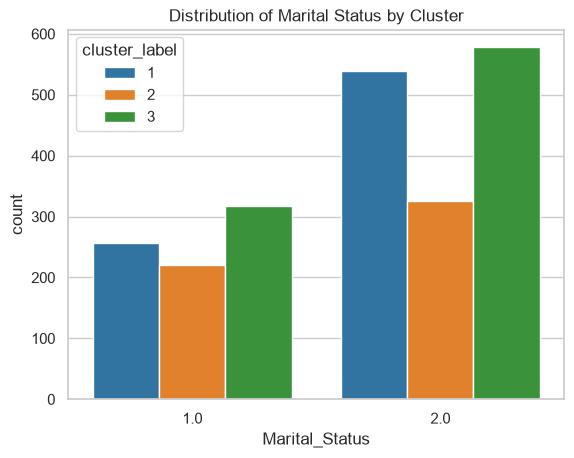

In [80]:
sns.countplot(data=df_prediction, x="Marital_Status", hue="cluster_label", palette="tab10")
plt.title("Distribution of Marital Status by Cluster")
plt.show()

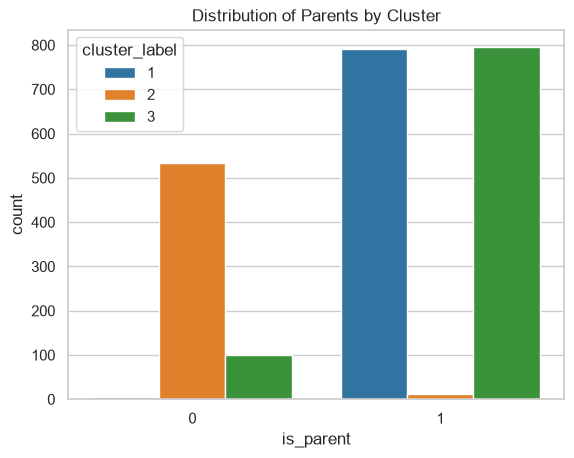

In [70]:
sns.countplot(data=df_prediction, x="is_parent", hue="cluster_label", palette="tab10")
plt.title("Distribution of Parents by Cluster")
plt.show()

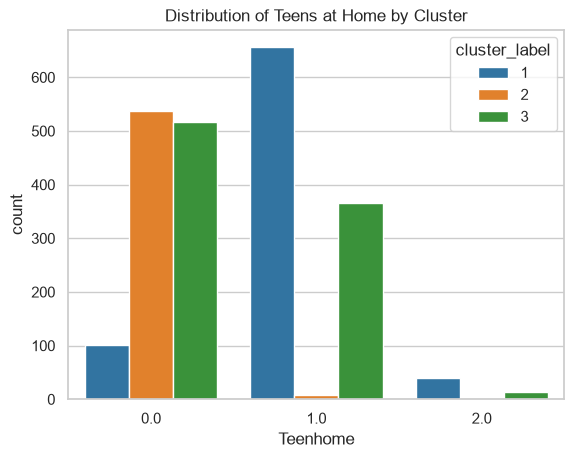

In [111]:
sns.countplot(data=df_prediction, x="Teenhome", hue="cluster_label", palette="tab10")
plt.title("Distribution of Teens at Home by Cluster")
plt.show()

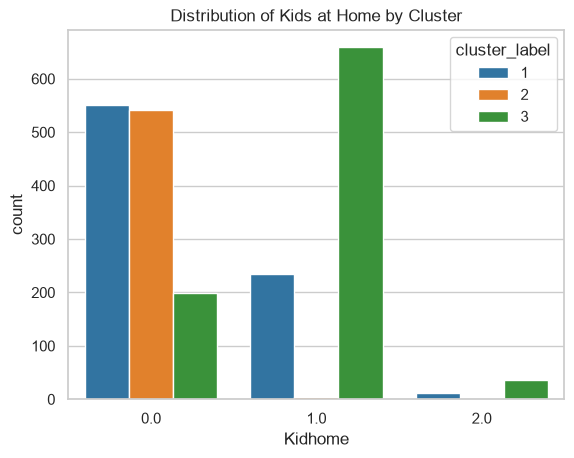

In [113]:
sns.countplot(data=df_prediction, x="Kidhome", hue="cluster_label", palette="tab10")
plt.title("Distribution of Kids at Home by Cluster")
plt.show()

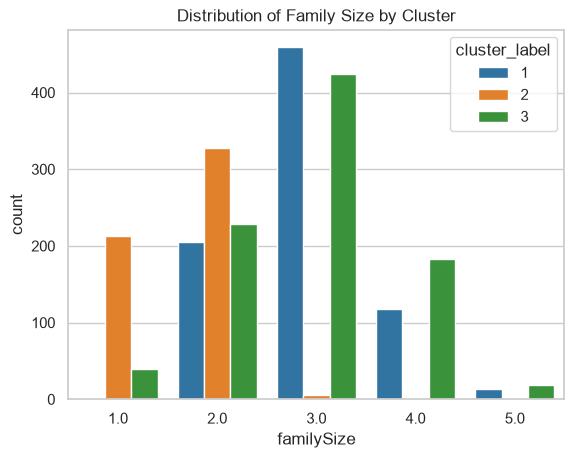

In [116]:
sns.countplot(data=df_prediction, x="familySize", hue="cluster_label", palette="tab10")
plt.title("Distribution of Family Size by Cluster")
plt.show()

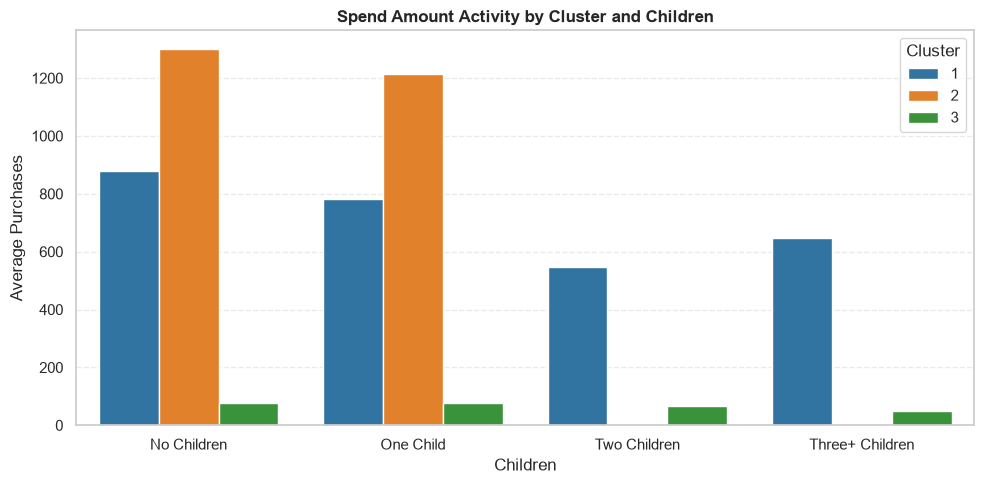

In [71]:
# spend amount by children and cluster

children_means = df_prediction.groupby(['cluster_label', 'children'])[['amountSpent']].mean()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(children_means, x="children", y="amountSpent", hue="cluster_label", palette="tab10")

#children_means.T.plot(kind='bar', ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Spend Amount Activity by Cluster and Children', fontweight='bold')
ax.set_xlabel('Children'); ax.set_ylabel('Average Purchases')
ax.set_xticklabels(['No Children','One Child','Two Children','Three+ Children'], rotation=0)
ax.legend(title='Cluster'); ax.grid(axis='y', linestyle='--', alpha=0.4)
fig.tight_layout()
#plt.savefig('../reports/figures/10_purchase_channels.png', dpi=150, bbox_inches='tight')
plt.show()

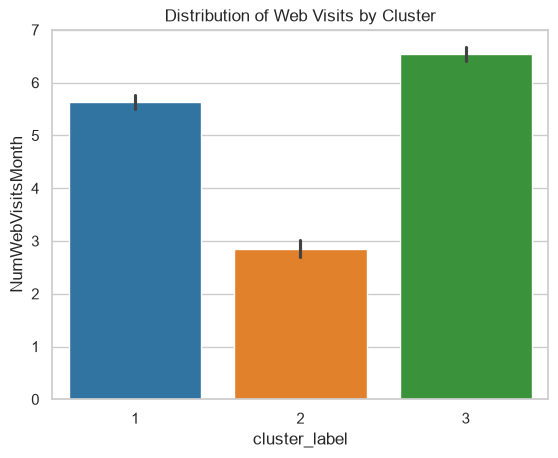

In [72]:
# Distribution of Web Visits by Cluster
sns.barplot(data=df_prediction, x="cluster_label", y="NumWebVisitsMonth", palette="tab10")
plt.title("Distribution of Web Visits by Cluster")
plt.show()

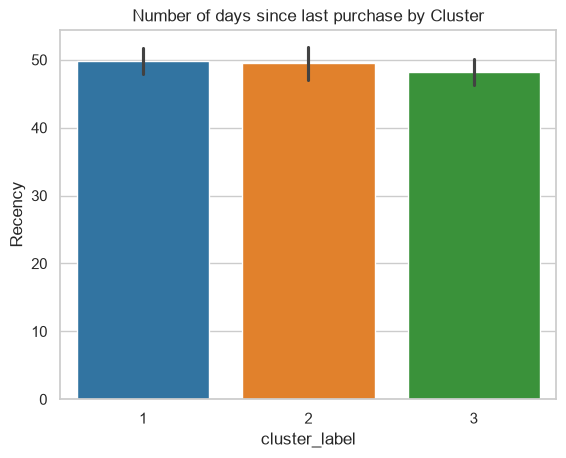

In [109]:
# Distribution of Web Visits by Cluster
sns.barplot(data=df_prediction, x="cluster_label", y="Recency", palette="tab10")
plt.title("Number of days since last purchase by Cluster")
plt.show()

## 7 · Cluster Summary

In [73]:
cols =["Income", "Age", "amountSpent", "numPurchases",
                "NumWebVisitsMonth", "Recency", "children", "familySize"]
summary = df_prediction.groupby("cluster_label")[cols].agg(["mean", "median", "std"]).round(2)
sizes   = df_prediction["cluster_label"].value_counts().sort_index()

print('Cluster sizes:')
for cluster, size in sizes.items():
    print(f'  Cluster {cluster}: {size:>5} customers ({100*size/sizes.sum():.1f}%)')

print()
print('Mean values per cluster:')
summary.xs('mean', axis=1, level=1).T

Cluster sizes:
  Cluster 1:   796 customers (35.6%)
  Cluster 2:   545 customers (24.4%)
  Cluster 3:   895 customers (40.0%)

Mean values per cluster:


cluster_label,1,2,3
Income,58598.33,73240.43,33067.23
Age,55.00,52.98,48.99
amountSpent,732.87,1297.59,71.99
numPurchases,20.28,19.69,7.13
NumWebVisitsMonth,5.64,2.85,6.54
Recency,49.82,49.52,48.25
children,1.24,0.02,1.26
familySize,2.92,1.62,2.90


#### Cluster 1:
* Medium-Income, Medium-Spending Customers
* Parents majority with Teens
* 2-4 Family Size
* High web visit activity
* High wine and gold purchases

#### Cluster 2:
* High-Income, High-Spending Customers
* Not Parents"
* 1-2 Family Size
* High web visit activity
* High purchases across all categories

#### Cluster 3:
* Low-Income, Low-Spending Customers
* Majority are Parents with kids
* 1-4 Family Size
* Low-to-medium web visit activity
* Low purchases across all categories


In [76]:
# save the predictions DataFrame to a CSV file
PREDICTIONS_PATH = '../data/predictions/customer_segmentation_predictions.csv'
os.makedirs(os.path.dirname(PREDICTIONS_PATH), exist_ok=True)
df_processed.to_csv(PREDICTIONS_PATH, index=False)

print(f"Predictions dataset saved with {df_prediction.shape[1]} columns.")

Predictions dataset saved with 25 columns.
